# Tutorial

## **Step 1: Importing the libraries**

In [1]:
import numpy as np
import OpenVisus as ov
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable

### The section below shows different LLC2160 fields we have available in cloud. 

### Set the variable.

In [2]:
variable='salt' # options are: u,v,w,salt,theta

In [3]:
# DONOT TOUCH
base_url= "https://nsdf-climate3-origin.nationalresearchplatform.org:50098/nasa/nsdf/climate3/dyamond/"
if variable=="theta" or variable=="w":
    base_dir=f"mit_output/llc2160_{variable}/llc2160_{variable}.idx"
elif variable=="u":
    base_dir= "mit_output/llc2160_arco/visus.idx"
else:
    base_dir=f"mit_output/llc2160_{variable}/{variable}_llc2160_x_y_depth.idx"


In [4]:
field= base_url+base_dir

## **Step 2: Reading the metadata file from cloud**
In this section, you can select any variables that you can declared in the cells above and replace it inside `LoadDataset`. We are just reading the metadata for the dataset here.

In [5]:
db=ov.LoadDataset(field)
print(f'Dimensions: {db.getLogicBox()[1][0]}*{db.getLogicBox()[1][1]}*{db.getLogicBox()[1][2]}')
print(f'Total Timesteps: {len(db.getTimesteps())}')
print(f'Field: {db.getField().name}')
print('Data Type: float32')

Dimensions: 8640*6480*90
Total Timesteps: 10366
Field: salt
Data Type: float32


## **Step 3:  Data Selection**
This section shows you how to load the data you want. You can select any timestep, region (x,y,z) you want. You can set the quality or resolution of the data as well. Higher quality means the finer(more) data. Not setting any time means first timestep available. Not setting quality means full data which takes a while to load because of the higher filesize. 

In [6]:
data=db.read(time=0,quality=-18,z=[0,1])
data.shape

(1, 102, 135)

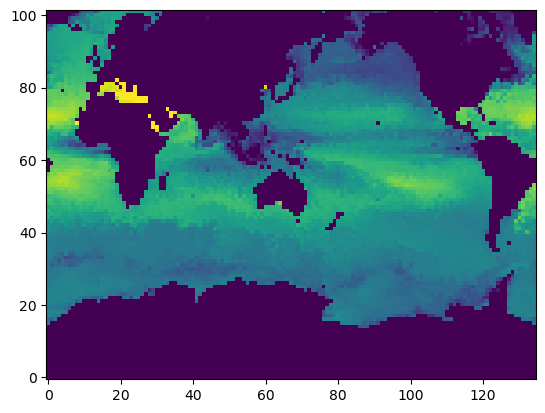

In [7]:
plt.imshow(data[0],origin='lower',vmin=31,vmax=38)

## **Step 4:  Visualize the data**
We are using a simple matplotlib here, but since the data is in numpy array, it can loaded with any python modules that support numpy. Feel free to set the `vmin`,`vmax` appropriately.

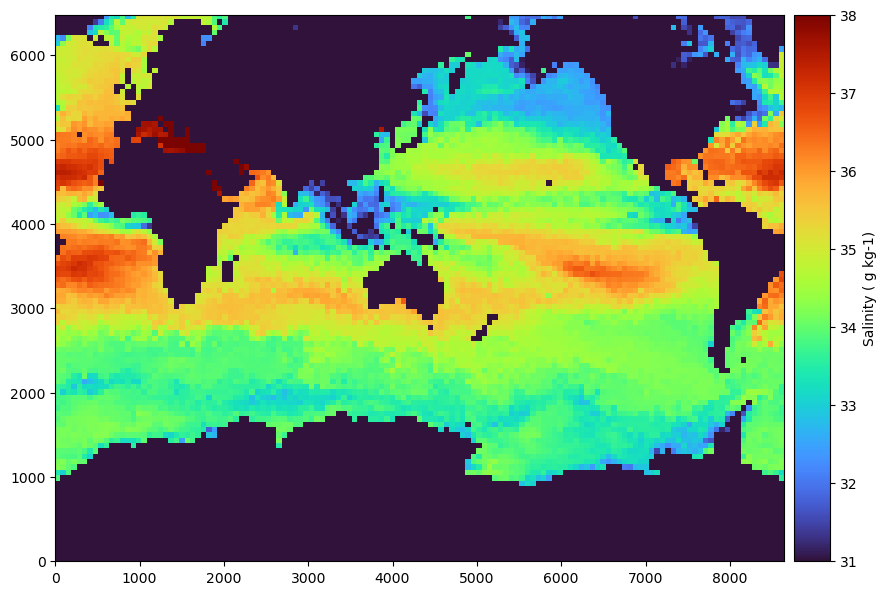

In [8]:
fig,axes=plt.subplots(1,1, figsize=(10,8))
axes.set_xlim(0,8640)
axes.set_ylim(0,6480)
im=axes.imshow(data[0,:,:],extent=[0,8640,0,6480],origin='lower',cmap='turbo',vmin=31,vmax=38)
divider = make_axes_locatable(axes)
cax = divider.append_axes("right",  size="5%", pad=0.1)  # Adjust size and pad as needed

cbar = plt.colorbar(im, cax=cax)
cbar.set_label('Salinity ( g kg-1)')
plt.show()

## **But, what if you want to see the full data for a certain region at a certain depth?**
Just set the right x,y,z while reading the data. x and y are the bounding box, z is the depth/layer. 

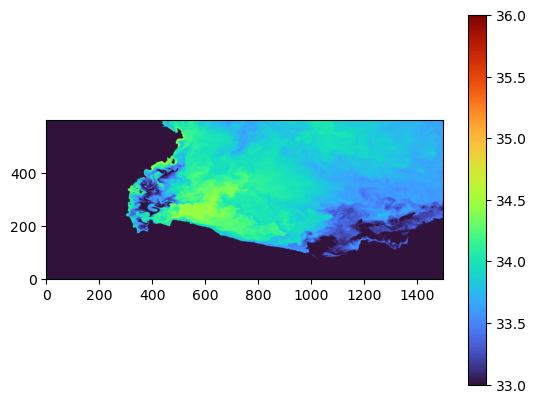

In [9]:
data1=db.read(time=0,z=[0,1],x=[4500,6000],y=[800,1400],quality=0)
plt.imshow(data1[0,:,:], origin='lower',vmin=33,vmax=36,cmap='turbo')
plt.colorbar()


## **Step 5: Save the data for the region locally**
You can save the data locally as you want. For example, here we are only saving the region shown above as a numpy array.

In [10]:
np.save('test_region1.npy', data1)

## **Step 6: Load the locally saved region and visualize using matplotlib**

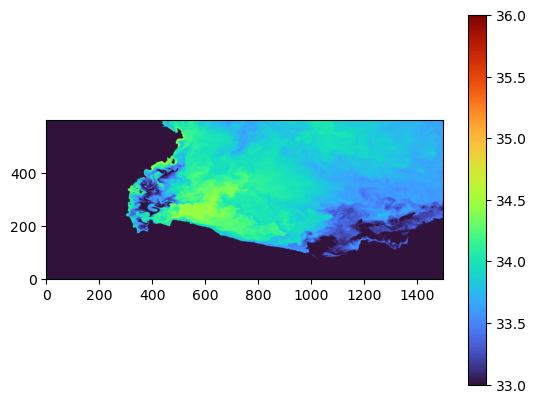

In [11]:
local_data=np.load('test_region1.npy')
plt.imshow(local_data[0,:,:], origin='lower',vmin=33,vmax=36,cmap='turbo')
plt.colorbar()

# **Lexy's Work**

I will be attempting to:
1. Perform PDA </br>
    a. see what variables are available in this dataset </br>
    b. see what times are available </br>
2. focus in on pre-determined lat and long
3. assign labels to data </br>
    a. variables </br>
    b. time / dates </br>
4. train model
5. predict with validation data

## 1a. Available variables

In [12]:
print(db.getFields())       # list fields

['salt']


The available variables are:
- salt:     Salinity — salt concentration in seawaterPSU (practical salinity units)
- u:        East-West velocity — horizontal current (zonal)m/s
- v:        North-South velocity — horizontal current (meridional)m/s
- w:        Vertical velocity — upward/downward water movementm/s
- theta:    Potential temperature — ocean water temperature°C

Which is consistent with the website information: https://sciviscontest2026.github.io/data/home#data2

## 1b. Available Times

In [13]:
print(max(db.getTimesteps()))    # list available timesteps too

10365


## 2. Focus on North Atlantic

In [14]:
import pandas as pd
import numpy as np
import datetime

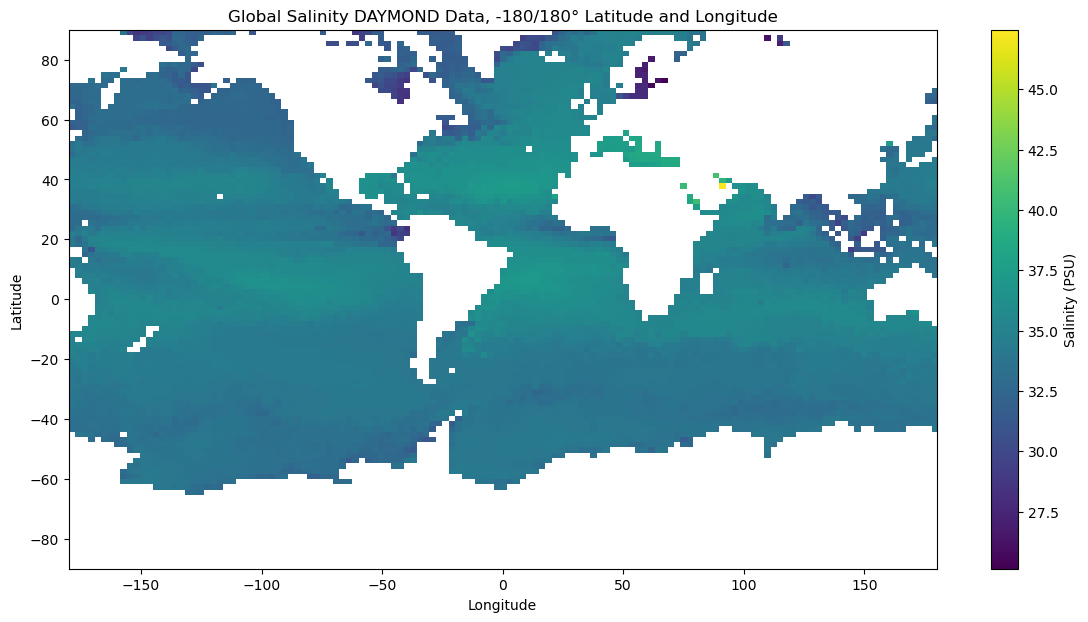

In [15]:
salt_raw = data[0]  # shape (102, 135)

# Roll the array so it goes -180→180 instead of 0→360
# Midpoint is at pixel index 135//2 = 67
salt_rolled = np.roll(salt_raw, shift=135//2, axis=1)  # shift columns by half

# Now build proper -180→180 coordinates
lons = np.linspace(-180, 180, 135)
lats = np.linspace(-90,   90, 102)

# Check it looks right globally first
plt.figure(figsize=(14, 7))
plt.imshow(np.where(salt_rolled > 1, salt_rolled, np.nan),
           origin='lower', aspect='auto',
           extent=[-180, 180, -90, 90])
plt.colorbar(label='Salinity (PSU)')
plt.title('Global Salinity DAYMOND Data, -180/180° Latitude and Longitude')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

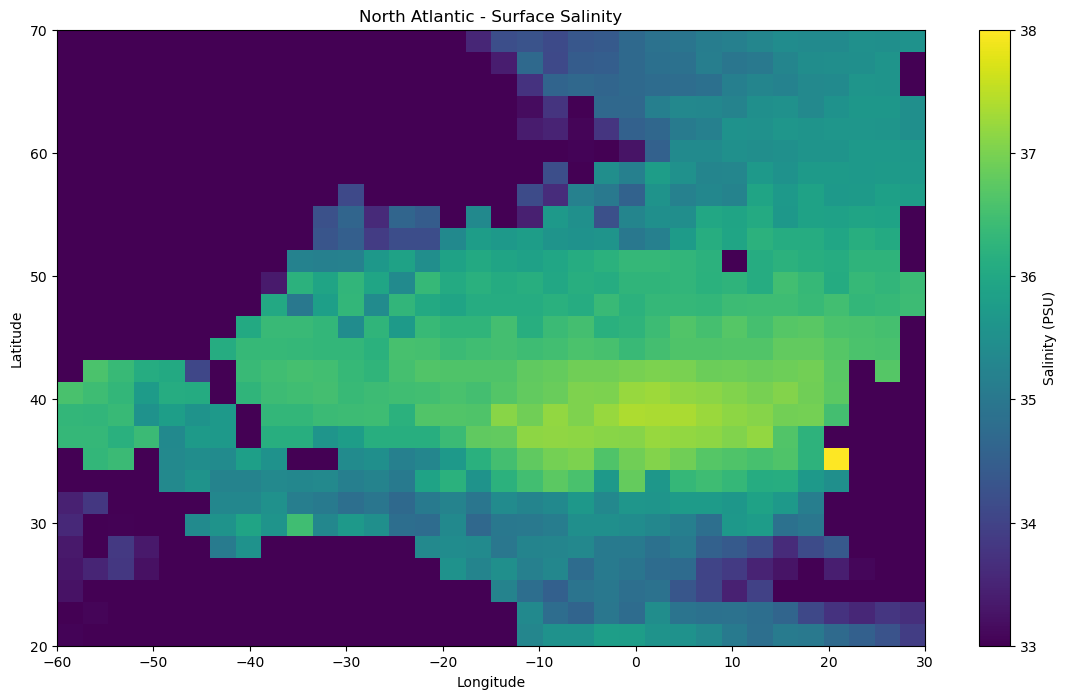

In [16]:
# Crop to hurricane map domain
lon_mask = (lons >= -60) & (lons <= 30)
lat_mask = (lats >=    20) & (lats <= 70)

salt_crop = salt_rolled[np.ix_(lat_mask, lon_mask)]

plt.figure(figsize=(14, 8))
plt.imshow(salt_crop, origin='lower', vmin=33, vmax=38, aspect='auto', extent=[-60, 30, 20, 70])
plt.colorbar(label='Salinity (PSU)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('North Atlantic - Surface Salinity')
plt.show()

## 3. Assign Labels

First, get time estimate for how long the dataframe creation will take.

In [17]:
# First, estimate time for 1 read
import time

start = time.time()
data = db.read(time=0, quality=-18, z=[0,1])
elapsed = time.time() - start
print(f"1 read: {elapsed:.2f} seconds")
print(f"Estimated total: {elapsed * 10366 / 60:.1f} minutes")

1 read: 0.28 seconds
Estimated total: 48.4 minutes


Then, save the data into a csv.

In [18]:
start_date = datetime.datetime(2020, 1, 20)
timesteps = range(0, max(db.getTimesteps()) + 1)

In [19]:
# Pre-build column names from lat/lon coordinates
lons_crop = lons[lon_mask]
lats_crop = lats[lat_mask]

# Each column = "salt_lat_lon"
columns = [
    f"salt_{lat:.2f}N_{lon:.2f}E"
    for lat in lats_crop
    for lon in lons_crop
]

In [42]:
sample_means = []
for t in range(0, 1000, 10):
    d = db.read(time=t, quality=-18, z=[0,1])[0]
    
    # Apply same roll and crop as main loop
    d_rolled = np.roll(d, shift=135//2, axis=1)
    d_crop   = d_rolled[np.ix_(lat_mask, lon_mask)]
    d_ocean  = np.where(d_crop > 1, d_crop, np.nan)
    total_cells = np.sum(~np.isnan(d_ocean))

    # Skip if no ocean cells
    if total_cells == 0:
        print(f"⚠️ Skipping t={t} — no valid ocean cells")
        continue
    
    mean = np.nanmean(d_ocean)
    if not np.isnan(mean):
        sample_means.append(mean)

global_mean = np.mean(sample_means)
print(f"Global mean salinity: {global_mean:.3f} PSU")
print(f"Samples used: {len(sample_means)}")

⚠️ Skipping t=430 — no valid ocean cells
Global mean salinity: 35.336 PSU
Samples used: 99


Try with test run first.

In [44]:
TEST_RUN = False
t_range = range(0, 50) if TEST_RUN else range(0, 10366)

In [45]:
records = []

for t in t_range:
    data = db.read(time=t, quality=-18, z=[0,1])
    salt_raw = data[0]
    
    salt_rolled = np.roll(salt_raw, shift=135//2, axis=1)
    salt_crop = salt_rolled[np.ix_(lat_mask, lon_mask)]
    salt_ocean = np.where(salt_crop > 1, salt_crop, np.nan)  # mask land
    total_cells = np.sum(~np.isnan(salt_ocean))

    # Skip if no ocean cells
    if total_cells == 0:
        print(f"⚠️ Skipping t={t} — no valid ocean cells")
        continue
    
    # --- engineered features ---
    
    # 1. Basic statistics
    mean_sal   = np.nanmean(salt_ocean)
    std_sal    = np.nanstd(salt_ocean)
    min_sal    = np.nanmin(salt_ocean)
    max_sal    = np.nanmax(salt_ocean)
    
    # 2. % of ocean cells in salinity brackets
    ocean_cells = np.sum(~np.isnan(salt_ocean))
    pct_low     = np.sum(salt_ocean < 34)              / ocean_cells  # fresh/diluted
    pct_mid     = np.sum((salt_ocean >= 34) & (salt_ocean < 36)) / ocean_cells  # normal
    pct_high    = np.sum(salt_ocean >= 36)             / ocean_cells  # very salty
    
    # 3. Spatial gradient (north vs south, east vs west)
    mid_lat = salt_ocean.shape[0] // 2
    mid_lon = salt_ocean.shape[1] // 2
    north_mean = np.nanmean(salt_ocean[mid_lat:, :])   # upper half
    south_mean = np.nanmean(salt_ocean[:mid_lat, :])   # lower half
    east_mean  = np.nanmean(salt_ocean[:, mid_lon:])   # right half
    west_mean  = np.nanmean(salt_ocean[:, :mid_lon])   # left half
    north_south_gradient = north_mean - south_mean
    east_west_gradient   = east_mean  - west_mean
    
    # 4. Anomaly — how different is this timestep from the mean?
    # (compute global_mean once before the loop)
    anomaly = mean_sal - global_mean
    
    # 5. Time features
    timestamp = start_date + datetime.timedelta(hours=t)
    
    records.append({
        "datetime":            timestamp.strftime("%m/%d/%Y-%H:00"),
        "mean_salinity":       mean_sal,
        "std_salinity":        std_sal,
        "min_salinity":        min_sal,
        "max_salinity":        max_sal,
        "pct_low_sal":         pct_low,       # < 34 PSU
        "pct_mid_sal":         pct_mid,       # 34-36 PSU
        "pct_high_sal":        pct_high,      # > 36 PSU
        "north_south_gradient": north_south_gradient,
        "east_west_gradient":  east_west_gradient,
        "anomaly":             anomaly
    })

    if t % 500 == 0:
        print(f"t={t} ({timestamp.strftime('%m/%d/%Y')})")

df = pd.DataFrame(records).set_index("datetime")
print(df.shape)   # (10366, 14) — much more manageable!
print(df.head())

t=0 (01/20/2020)
⚠️ Skipping t=43 — no valid ocean cells
⚠️ Skipping t=422 — no valid ocean cells
⚠️ Skipping t=428 — no valid ocean cells
⚠️ Skipping t=429 — no valid ocean cells
⚠️ Skipping t=430 — no valid ocean cells
⚠️ Skipping t=431 — no valid ocean cells
⚠️ Skipping t=432 — no valid ocean cells
⚠️ Skipping t=433 — no valid ocean cells
⚠️ Skipping t=434 — no valid ocean cells
⚠️ Skipping t=435 — no valid ocean cells
t=500 (02/09/2020)
t=1000 (03/01/2020)
t=1500 (03/22/2020)
t=2000 (04/12/2020)
⚠️ Skipping t=2178 — no valid ocean cells
t=2500 (05/03/2020)
⚠️ Skipping t=2880 — no valid ocean cells
t=3000 (05/24/2020)
t=3500 (06/13/2020)
t=4000 (07/04/2020)
⚠️ Skipping t=4219 — no valid ocean cells
⚠️ Skipping t=4220 — no valid ocean cells
⚠️ Skipping t=4221 — no valid ocean cells
⚠️ Skipping t=4222 — no valid ocean cells
⚠️ Skipping t=4223 — no valid ocean cells
⚠️ Skipping t=4272 — no valid ocean cells
⚠️ Skipping t=4273 — no valid ocean cells
⚠️ Skipping t=4274 — no valid ocean c

In [46]:
df.to_csv("atlantic_salt_full.csv", index=True)
print("Done!", df.shape)

Done! (10269, 10)


In [47]:
print(df.shape)
print(df.head())
print(df.isna().sum())

(10269, 10)
                  mean_salinity  std_salinity  min_salinity  max_salinity  \
datetime                                                                    
01/20/2020-00:00      35.253307      1.530607     28.236942     37.999664   
01/20/2020-01:00      35.254341      1.530209     28.221603     38.002983   
01/20/2020-02:00      35.255333      1.529801     28.219584     38.012333   
01/20/2020-03:00      35.256042      1.529577     28.224401     38.018192   
01/20/2020-04:00      35.256413      1.529338     28.233688     38.016647   

                  pct_low_sal  pct_mid_sal  pct_high_sal  \
datetime                                                   
01/20/2020-00:00     0.164948     0.463918      0.371134   
01/20/2020-01:00     0.164948     0.463918      0.371134   
01/20/2020-02:00     0.164948     0.462445      0.372607   
01/20/2020-03:00     0.164948     0.462445      0.372607   
01/20/2020-04:00     0.163476     0.463918      0.372607   

                  north_sou

In [48]:
import os
print("Current directory:", os.getcwd())
print("Files here:", os.listdir("."))

Current directory: /home/exouser/Project/data-engineering-project-acandershock
Files here: ['.gitignore', 'project-code', 'build_jetstream_environment.sh', 'test_region1.npy', '.ipynb_checkpoints', 'LICENSE', 'atlantic_salt_full.csv', 'jetstream2_manual.pdf', 'README.md', '.git', 'task2_weather_events', 'environment.yml']


You have to go download the notebook from Jupyter labs! It won't download on the local machine.

## 3. Label Target Data

In [49]:
# start logic
# Step 1 — define your hurricane dates (from the 2020 season NOAA map)
# Add whatever date ranges apply
hurricane_dates = [
    # (start, end, name) — from the NOAA chart
    ("05/16/2020", "05/19/2020", "Arthur"),
    ("05/27/2020", "05/28/2020", "Bertha"),
    ("06/01/2020", "06/09/2020", "Cristobal"),
    ("07/23/2020", "07/26/2020", "Gonzalo"),
    ("08/01/2020", "08/04/2020", "Isaias"),
    ("08/20/2020", "08/29/2020", "Laura"),
    ("08/20/2020", "08/29/2020", "Marco"),
    ("09/07/2020", "09/22/2020", "Sally"),
    ("09/12/2020", "09/23/2020", "Teddy"),
    ("10/19/2020", "10/26/2020", "Delta"),
    ("10/24/2020", "10/29/2020", "Zeta"),
    ("10/31/2020", "11/13/2020", "Eta"),
    ("11/13/2020", "11/18/2020", "Iota"),
    # add more as needed...
]

# Step 2 — build a set of all hurricane dates
from datetime import datetime, timedelta

active_hurricane_days = set()

for start_str, end_str, name in hurricane_dates:
    start = datetime.strptime(start_str, "%m/%d/%Y")
    end   = datetime.strptime(end_str,   "%m/%d/%Y")
    current = start
    while current <= end:
        active_hurricane_days.add(current.strftime("%m/%d/%Y"))
        current += timedelta(days=1)

print(f"Total hurricane days: {len(active_hurricane_days)}")

# Step 3 — add binary column to your DataFrame
# df.index is already in "%m/%d/%Y" format
df["hurricane"] = df.index.map(
    lambda dt: 1 if dt.split("-")[0] in active_hurricane_days else 0
)

print(df["hurricane"].value_counts())
print(df.head())

Total hurricane days: 80
hurricane
0    8350
1    1919
Name: count, dtype: int64
                  mean_salinity  std_salinity  min_salinity  max_salinity  \
datetime                                                                    
01/20/2020-00:00      35.253307      1.530607     28.236942     37.999664   
01/20/2020-01:00      35.254341      1.530209     28.221603     38.002983   
01/20/2020-02:00      35.255333      1.529801     28.219584     38.012333   
01/20/2020-03:00      35.256042      1.529577     28.224401     38.018192   
01/20/2020-04:00      35.256413      1.529338     28.233688     38.016647   

                  pct_low_sal  pct_mid_sal  pct_high_sal  \
datetime                                                   
01/20/2020-00:00     0.164948     0.463918      0.371134   
01/20/2020-01:00     0.164948     0.463918      0.371134   
01/20/2020-02:00     0.164948     0.462445      0.372607   
01/20/2020-03:00     0.164948     0.462445      0.372607   
01/20/2020-04:00   

## 4. Train Model

In [ ]:
!pip install xgboost

In [51]:
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import matplotlib.pyplot as plt
import numpy as np

# Step 1 — separate features and target
X = df.drop(columns=["hurricane"])
y = df["hurricane"]

print("Class balance:")
print(y.value_counts())
# ⚠️ likely very imbalanced — mostly 0s!

# Step 2 — train/test split
# Time-based split — no shuffling, earlier dates train, later dates test
# Your index is "MM/DD/YYYY-HH:00" so order is already chronological

# Step 2 — train/test split
# Push split later so model sees more hurricane season
split_date = "09/15/2020-00:00"

split_idx = df.index.get_loc(split_date)

X_train = X.iloc[:split_idx]
X_test  = X.iloc[split_idx:]
y_train = y.iloc[:split_idx]
y_test  = y.iloc[split_idx:]

print(f"Train: {X_train.index[0]} → {X_train.index[-1]}")
print(f"Test:  {X_test.index[0]}  → {X_test.index[-1]}")
print(f"Hurricane hours in train: {(y_train==1).sum()}")
print(f"Hurricane hours in test:  {(y_test==1).sum()}")

# Step 3 — handle class imbalance
# Count ratio of non-hurricane to hurricane hours
scale_pos_weight = float((y_train == 0).sum() / (y_train == 1).sum())
print(f"scale_pos_weight: {scale_pos_weight:.2f}")

# Step 4 — train XGBoost
model = xgb.XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    scale_pos_weight=scale_pos_weight,  # handles imbalance
    eval_metric="auc",
    random_state=42,
    n_jobs=-1
)

model.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    verbose=50
)

Class balance:
hurricane
0    8350
1    1919
Name: count, dtype: int64
Train: 01/20/2020-00:00 → 09/14/2020-23:00
Test:  09/15/2020-00:00  → 03/26/2021-21:00
Hurricane hours in train: 983
Hurricane hours in test:  936
scale_pos_weight: 4.74
[0]	validation_0-auc:0.78180
[50]	validation_0-auc:0.88647
[100]	validation_0-auc:0.88292
[150]	validation_0-auc:0.86985
[199]	validation_0-auc:0.86522


,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes 

In [52]:
# Step 5 — evaluate
y_pred  = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["No Hurricane", "Hurricane"]))
print("ROC-AUC Score:", roc_auc_score(y_test, y_proba))


Classification Report:
              precision    recall  f1-score   support

No Hurricane       0.94      0.82      0.88      3694
   Hurricane       0.53      0.81      0.64       936

    accuracy                           0.82      4630
   macro avg       0.74      0.81      0.76      4630
weighted avg       0.86      0.82      0.83      4630

ROC-AUC Score: 0.8652170128043165


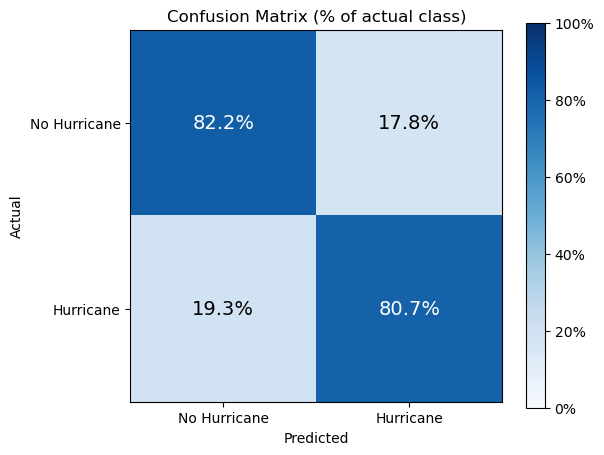

In [59]:
from matplotlib.ticker import FuncFormatter

cm = confusion_matrix(y_test, y_pred, normalize='true')

plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap="Blues", vmin=0, vmax=1)
cb = plt.colorbar()
cb.ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0%}"))
plt.xticks([0, 1], ["No Hurricane", "Hurricane"])
plt.yticks([0, 1], ["No Hurricane", "Hurricane"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
for i in range(2):
    for j in range(2):
        plt.text(j, i, f"{cm[i, j]:.1%}", ha="center", va="center",
                 fontsize=14, color="white" if cm[i, j] > 0.5 else "black")
plt.title("Confusion Matrix (% of actual class)")
plt.show()

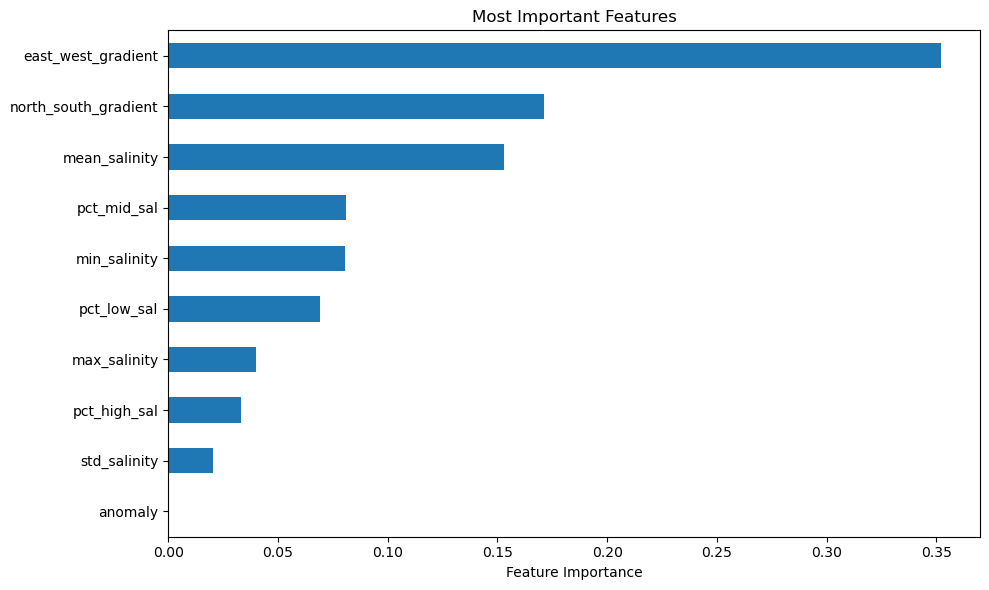

In [55]:
# Step 7 — top features
feat_imp = pd.Series(model.feature_importances_, index=X.columns)
top20 = feat_imp.nlargest(20)

plt.figure(figsize=(10, 6))
top20.sort_values().plot(kind="barh")
plt.title("Most Important Features")
plt.xlabel("Feature Importance")
plt.tight_layout()
plt.show()